# Sign Language Digits: MLP vs CNN, Hyperparameter Search and Robustness to Noise

**Author:** Stylianos Stamatis · MSc Machine Learning (University of Thessaly), *Machine Learning – Deep Learning* project

Classify hand-sign images of the digits 0–9 (2,062 grayscale images, 64 × 64).
The notebook compares a **multilayer perceptron (MLP)** with a **convolutional neural network (CNN)**, tunes both on a validation set,
reports test metrics averaged over several random seeds, and studies **robustness to Gaussian noise**
(a denoising autoencoder vs. training with noise augmentation).

| Section | Content |
|---|---|
| 1 | Data loading and checks |
| 2 | Exploratory analysis: class balance, mean images, class similarity, PCA |
| 3 | Reproducible training setup: seeds, checkpointing, early stopping |
| 4 | Hyperparameter search for MLP and CNN (validation set) |
| 5 | Final comparison over 5 seeds: accuracy, precision, recall, F1, ROC-AUC, learning curves |
| 6 | Robustness to noise: clean CNN, DAE + CNN, CNN trained on denoised data, CNN with noise augmentation |

Set `TRAIN = False` to skip training and load the saved weights and histories from `checkpoints/`.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import json, subprocess, time, warnings
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
import keras
from keras import layers

from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
TRAIN = True            # False: load saved weights/histories instead of training (if they exist)

keras.utils.set_random_seed(SEED)            # Python, NumPy and TensorFlow seeds in one call
tf.config.experimental.enable_op_determinism()

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, FIG_DIR, CKPT_DIR = ROOT / "data", ROOT / "figures", ROOT / "checkpoints"
for d in (DATA_DIR, FIG_DIR, CKPT_DIR):
    d.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
def save(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| GPU:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow 2.21.0 | Keras 3.15.1 | GPU: False


## 1. Data

Source: [Sign Language Digits Dataset](https://github.com/ardamavi/Sign-Language-Digits-Dataset) (Mavi, 2020), photographed at Ankara Ayrancı Anadolu High School.
The images are read from the **per-digit folders** of the original repository, converted to grayscale and resized to 64 × 64.
Labels therefore come from the folder names. (Users of the `X.npy`/`Y.npy` copy on Kaggle have reported that its label indices do not match the digit shown. That does not change accuracy, but it does change which digits appear to be confused with each other.)

In [2]:
CACHE = DATA_DIR / "sign_digits_64.npz"
if not CACHE.exists():
    raw = DATA_DIR / "raw"
    if not raw.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/ardamavi/Sign-Language-Digits-Dataset", str(raw)], check=True)
    imgs, labels = [], []
    for digit in range(10):
        for f in sorted((raw / "Dataset" / str(digit)).iterdir()):
            imgs.append(np.asarray(Image.open(f).convert("L").resize((64, 64), Image.LANCZOS), dtype=np.uint8))
            labels.append(digit)
    np.savez_compressed(CACHE, X=np.stack(imgs), y=np.array(labels))

d = np.load(CACHE)
X = d["X"].astype("float32") / 255.0          # scale pixels to [0, 1]
y = d["y"].astype("int64")
print(f"X: {X.shape}, {X.dtype}, range [{X.min():.2f}, {X.max():.2f}]   y: {y.shape}, classes {np.unique(y)}")
print(f"Missing / infinite values: {int(np.isnan(X).sum())} NaN, {int(np.isinf(X).sum())} Inf")
pd.Series(np.bincount(y), name="images per class").to_frame().T

X: (2062, 64, 64), float32, range [0.00, 1.00]   y: (2062,), classes [0 1 2 3 4 5 6 7 8 9]
Missing / infinite values: 0 NaN, 0 Inf


,0,1,2,3,4,5,6,7,8,9
images per class,205,206,206,206,207,207,207,206,208,204


## 2. Exploratory analysis

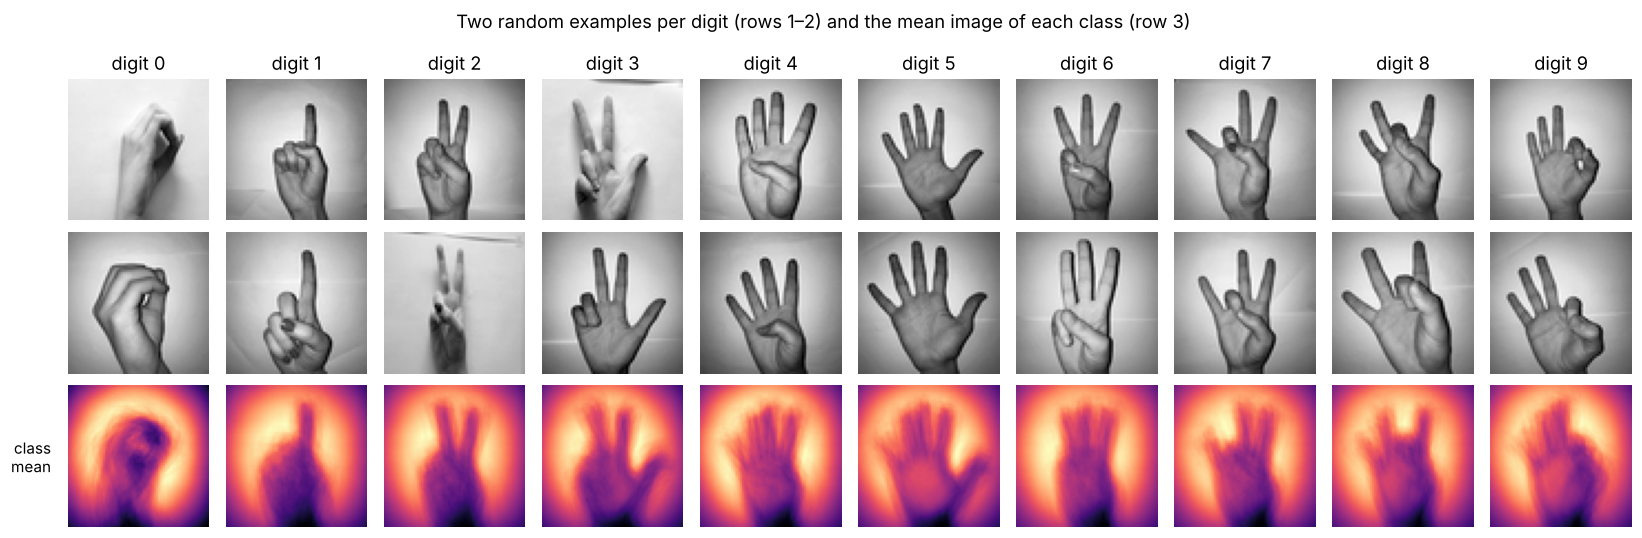

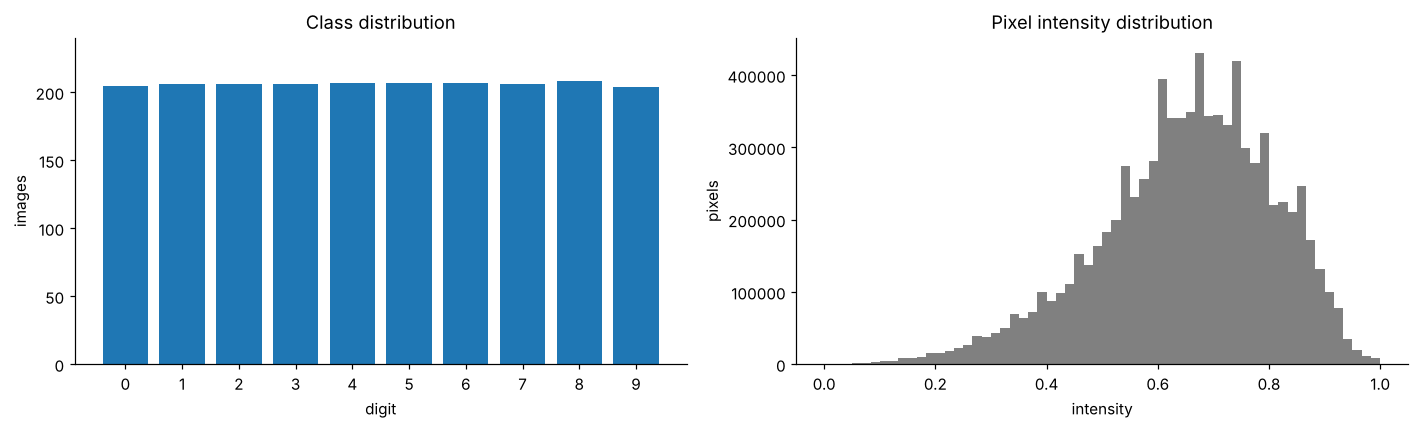

In [3]:
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(3, 10, figsize=(15, 5))
for dgt in range(10):
    idx = rng.choice(np.where(y == dgt)[0], 2, replace=False)
    for r in range(2):
        ax[r, dgt].imshow(X[idx[r]], cmap="gray"); ax[r, dgt].axis("off")
    ax[0, dgt].set_title(f"digit {dgt}")
    ax[2, dgt].imshow(X[y == dgt].mean(0), cmap="magma"); ax[2, dgt].axis("off")
ax[2, 0].text(-8, 32, "class\nmean", ha="right", va="center", fontsize=10)
plt.suptitle("Two random examples per digit (rows 1–2) and the mean image of each class (row 3)")
plt.tight_layout(); save("eda_examples"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(range(10), np.bincount(y), color="tab:blue"); ax[0].set_xticks(range(10))
ax[0].set(title="Class distribution", xlabel="digit", ylabel="images", ylim=(0, 240))
ax[1].hist(X.ravel(), bins=60, color="gray"); ax[1].set(title="Pixel intensity distribution", xlabel="intensity", ylabel="pixels")
plt.tight_layout(); save("eda_distributions"); plt.show()

**Correlations.** For images, "correlation" is most informative between classes: the Pearson correlation between class-mean images
shows which signs look alike on average, and a 2-D PCA projection shows whether the classes are separable using raw pixel intensities.

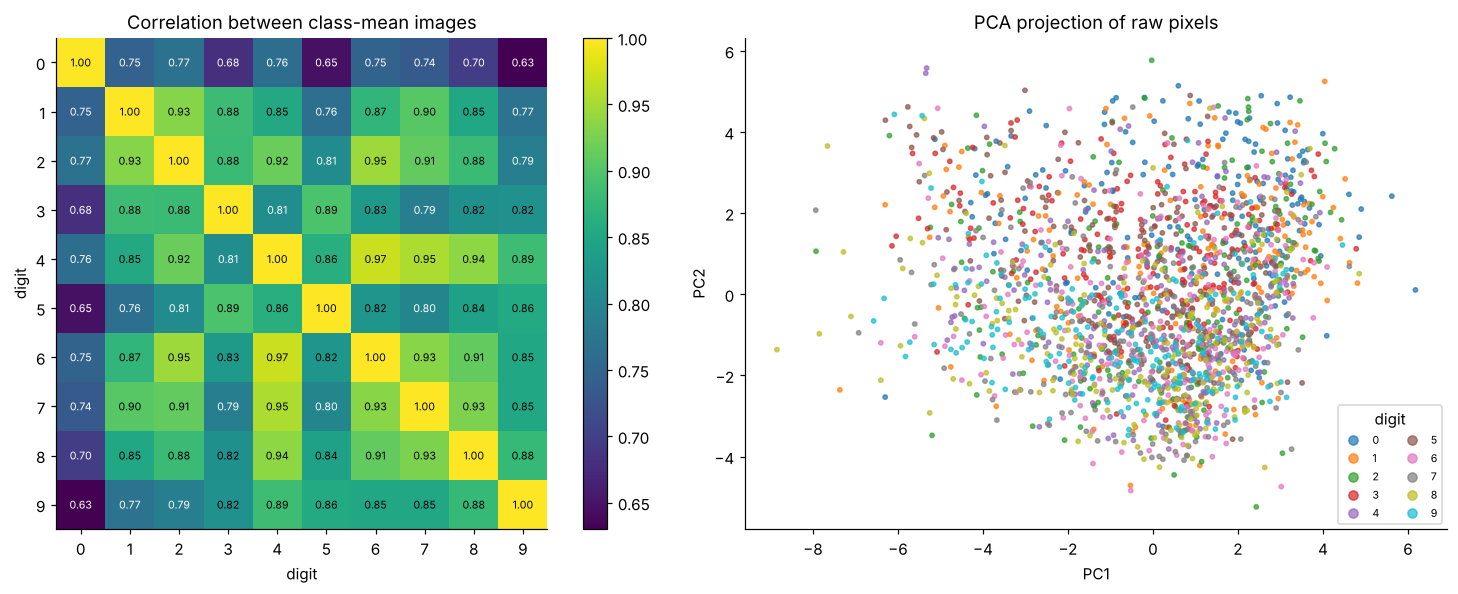

Most similar class pairs (mean-image correlation): 4–6: 0.970, 4–7: 0.954, 2–6: 0.946, 4–8: 0.937, 6–7: 0.935
Variance explained by the first 2 / 10 / 50 principal components: 14.3% / 37.8% / 67.2%


In [4]:
means = np.stack([X[y == k].mean(0).ravel() for k in range(10)])
corr = np.corrcoef(means)
pca = PCA(n_components=50, random_state=SEED).fit(X.reshape(len(X), -1))
Z = pca.transform(X.reshape(len(X), -1))[:, :2]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
im = ax[0].imshow(corr, cmap="viridis", vmin=corr.min(), vmax=1)
for i in range(10):
    for j in range(10):
        ax[0].text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", fontsize=7,
                   color="white" if corr[i, j] < (corr.min() + 1) / 2 else "black")
ax[0].set_xticks(range(10)); ax[0].set_yticks(range(10))
ax[0].set(title="Correlation between class-mean images", xlabel="digit", ylabel="digit"); plt.colorbar(im, ax=ax[0])
sc = ax[1].scatter(Z[:, 0], Z[:, 1], c=y, cmap="tab10", s=8, alpha=0.7)
ax[1].legend(*sc.legend_elements(), title="digit", fontsize=7, ncol=2, loc="lower right")
ax[1].set(title="PCA projection of raw pixels", xlabel="PC1", ylabel="PC2")
plt.tight_layout(); save("eda_correlation_pca"); plt.show()

off = corr.copy(); np.fill_diagonal(off, np.nan)
pairs = sorted(((off[i, j], i, j) for i in range(10) for j in range(i + 1, 10)), reverse=True)[:5]
print("Most similar class pairs (mean-image correlation):", ", ".join(f"{i}–{j}: {c:.3f}" for c, i, j in pairs))
print(f"Variance explained by the first 2 / 10 / 50 principal components: "
      f"{pca.explained_variance_ratio_[:2].sum():.1%} / {pca.explained_variance_ratio_[:10].sum():.1%} / {pca.explained_variance_ratio_.sum():.1%}")

**Interpretation**

* **Clean, balanced data.** No missing or infinite values; 204–208 images per class. Accuracy is therefore a fair headline metric, and macro and weighted averages coincide.
* **Mean images** show a consistent setup: the hand is centred on a bright background, so most of the variation is in the fingers. Digit 0 (a closed, curved hand) is the most distinctive class: its mean image correlates only 0.63–0.77 with the others.
* **Similar signs.** The most correlated class means are **4–6 (0.97)**, 4–7 (0.95), 2–6 (0.95), 4–8 (0.94) and 6–7 (0.94). These are open-hand signs that differ only in which fingers are raised or touching the thumb, so they are the pairs a classifier is most likely to confuse.
* **PCA.** The first two principal components explain only 14% of the pixel variance (50 components: 67%), and the classes overlap completely in the 2-D projection. Raw pixel intensities are not linearly separable by digit; the information lies in local shapes (finger positions), which is exactly what convolutions are designed to detect.

## 3. Reproducible training setup

**Split.** Stratified 70 / 15 / 15 into train / validation / test. The **test set is used only once, for the final comparison**;
all choices (epochs, hyperparameters, thresholds) are made on the validation set.

**Training rules** (the source of the problems in the first version of this project):
* Every experiment builds a **new model** and trains it **from scratch**. Weights from earlier runs are never loaded before training, because that silently continues training, so results would depend on how many times a cell was run.
* `EarlyStopping(restore_best_weights=True)` keeps the epoch with the lowest validation loss; `ModelCheckpoint(save_best_only=True)` writes the same weights to disk (useful when Colab disconnects).
* Early stopping (patience 10, at most 100 epochs) only starts counting after **epoch 10**. Heavily regularised CNNs (dropout 0.5, augmentation, input noise) can sit on the initial plateau (loss ≈ ln 10 = 2.30, i.e. chance) for several epochs; without this, one run was stopped before it ever started learning.
* Saved weights are loaded **only** when `TRAIN = False`, i.e. to evaluate without retraining. The training history is saved next to the weights so the learning curves can be redrawn.
* `keras.utils.set_random_seed` fixes the Python, NumPy and TensorFlow seeds; `enable_op_determinism` makes TensorFlow operations deterministic.

Labels are integers, so the loss is `sparse_categorical_crossentropy` (equivalent to categorical cross-entropy on one-hot labels).

In [5]:
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
X_tr, X_va, X_te = X_tr[..., None], X_va[..., None], X_te[..., None]     # add channel axis: (64, 64, 1)
print(f"train {X_tr.shape}, validation {X_va.shape}, test {X_te.shape}")

def fit(build_fn, cfg, name, X_train, y_train, X_val, y_val, seed=SEED, max_epochs=100, patience=10):
    # Build a fresh model and train it from scratch, or load saved weights when TRAIN is False
    keras.utils.set_random_seed(seed)
    model = build_fn(cfg)
    w_path, h_path = CKPT_DIR / f"{name}.weights.h5", CKPT_DIR / f"{name}.history.json"
    if not TRAIN and w_path.exists() and h_path.exists():
        model.load_weights(w_path)
        return model, json.loads(h_path.read_text())
    t0 = time.time()
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=max_epochs,
                     batch_size=cfg.get("batch", 32), verbose=0,
                     callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True,
                                                              start_from_epoch=10),
                                keras.callbacks.ModelCheckpoint(w_path, monitor="val_loss", save_best_only=True,
                                                                save_weights_only=True)]).history
    hist = {k: [float(v) for v in vals] for k, vals in hist.items()}
    hist["seconds"] = time.time() - t0
    h_path.write_text(json.dumps(hist))
    return model, hist

def best_epoch(hist):
    return int(np.argmin(hist["val_loss"]))

train (1443, 64, 64, 1), validation (309, 64, 64, 1), test (310, 64, 64, 1)


## 4. Models and hyperparameter search

**MLP.** Flatten (4,096 inputs) → dense hidden layers with ReLU and dropout → softmax over 10 classes.
Inputs are standardised (training-set mean and standard deviation): with raw [0, 1] pixels and higher learning rates the MLP trained unstably (many ReLU units stop activating), and in quick tests batch normalisation made it overfit badly.
It ignores the spatial arrangement of pixels: shifting the hand by a few pixels changes almost every input feature.

**CNN.** Three convolution blocks (Conv 3×3 + ReLU + max-pooling; 32 → 64 → 128 filters) learn local patterns
(edges, finger contours) with weights shared across positions, followed by Flatten (8 × 8 × 128 = 8,192 features) → Dense(128) → dropout → softmax.
The grid varies the learning rate, the dropout rate and data augmentation.

**Data augmentation** (CNN, training only): random rotation (±18°), shift (±8%) and zoom (±10%), to mimic natural variation in hand position with only 1,443 training images.

Each grid point is trained once (seed 42) and scored on the validation set. The **original configuration** of the first version is included for reference.

In [6]:
def build_mlp(cfg):
    m = keras.Sequential([layers.Input((64, 64, 1)), layers.Flatten()])
    if cfg.get("standardize"):
        m.add(layers.Normalization(mean=float(X_tr.mean()), variance=float(X_tr.var())))   # training-set pixel mean / variance
    for units in cfg["hidden"]:
        m.add(layers.Dense(units, activation="relu"))
        m.add(layers.Dropout(cfg["dropout"]))
    m.add(layers.Dense(10, activation="softmax"))
    m.compile(keras.optimizers.Adam(cfg["lr"]), "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

AUGMENT = [layers.RandomRotation(0.05, fill_mode="nearest"), layers.RandomTranslation(0.08, 0.08, fill_mode="nearest"),
           layers.RandomZoom(0.1, fill_mode="nearest")]

def build_cnn(cfg):
    m = keras.Sequential([layers.Input((64, 64, 1))])
    if cfg.get("noise"):
        m.add(layers.GaussianNoise(cfg["noise"]))          # active only during training
    if cfg.get("augment"):
        for aug in AUGMENT:
            m.add(aug.__class__.from_config(aug.get_config()))
    for filters in (32, 64, 128):
        m.add(layers.Conv2D(filters, 3, padding="same", activation="relu"))
        m.add(layers.MaxPooling2D())
    m.add(layers.Flatten())
    m.add(layers.Dense(128, activation="relu"))
    m.add(layers.Dropout(cfg["dropout"]))
    m.add(layers.Dense(10, activation="softmax"))
    m.compile(keras.optimizers.Adam(cfg["lr"]), "sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def describe(cfg):
    return ", ".join(f"{k}={v}" for k, v in cfg.items() if k != "batch")

def search(build_fn, grid, prefix):
    path = CKPT_DIR / f"{prefix}_search.csv"
    if not TRAIN and path.exists():
        return pd.read_csv(path)
    rows = []
    for i, cfg in enumerate(grid):
        model, h = fit(build_fn, cfg, f"{prefix}_search_{i}", X_tr, y_tr, X_va, y_va)
        b = best_epoch(h)
        rows.append({"config": describe(cfg), "params": model.count_params(), "best epoch": b + 1,
                     "train acc": h["accuracy"][b], "val acc": h["val_accuracy"][b], "val loss": h["val_loss"][b],
                     "seconds": round(h["seconds"], 1), "cfg": json.dumps(cfg)})
    res = pd.DataFrame(rows)
    res.to_csv(path, index=False)
    return res

In [7]:
MLP_ORIGINAL = {"hidden": [256, 125], "dropout": 0.1, "lr": 1e-3, "batch": 64}
mlp_grid = [MLP_ORIGINAL] + [{"hidden": h, "dropout": dr, "lr": 1e-4, "standardize": True}
                             for h, dr in product([[256, 128], [512, 256], [1024, 256]], [0.2, 0.5])]
mlp_res = search(build_mlp, mlp_grid, "mlp")
mlp_res.insert(0, "label", ["original"] + [f"M{i}" for i in range(1, len(mlp_res))])
mlp_res.sort_values(["val acc", "val loss"], ascending=[False, True]).drop(columns="cfg").round(4)

,label,config,params,best epoch,train acc,val acc,val loss,seconds
2,M2,"hidden=[256, 128], dropout=0.5, lr=0.0001, sta...",1083018,36,0.8725,0.7735,0.7754,23.9
5,M5,"hidden=[1024, 256], dropout=0.2, lr=0.0001, st...",4460298,13,0.9917,0.7735,0.8355,30.1
6,M6,"hidden=[1024, 256], dropout=0.5, lr=0.0001, st...",4460298,26,0.9328,0.7638,0.7919,44.1
4,M4,"hidden=[512, 256], dropout=0.5, lr=0.0001, sta...",2231562,24,0.9016,0.7605,0.7501,25.7
1,M1,"hidden=[256, 128], dropout=0.2, lr=0.0001, sta...",1083018,11,0.9148,0.7508,0.8090,10.8
3,M3,"hidden=[512, 256], dropout=0.2, lr=0.0001, sta...",2231562,8,0.9196,0.7346,0.8167,22.4
0,original,"hidden=[256, 125], dropout=0.1, lr=0.001",1082217,20,0.6930,0.6828,0.9836,11.1


In [8]:
CNN_ORIGINAL = {"dropout": 0.3, "lr": 1e-3, "augment": False, "batch": 64}
cnn_grid = [CNN_ORIGINAL] + [{"dropout": dr, "lr": lr, "augment": au}
                             for lr, au, dr in product([1e-3, 3e-4], [False, True], [0.3, 0.5])]
cnn_res = search(build_cnn, cnn_grid, "cnn")
cnn_res.insert(0, "label", ["original"] + [f"C{i}" for i in range(1, len(cnn_res))])
cnn_res.sort_values(["val acc", "val loss"], ascending=[False, True]).drop(columns="cfg").round(4)

,label,config,params,best epoch,train acc,val acc,val loss,seconds
4,C4,"dropout=0.5, lr=0.001, augment=True",1142666,44,0.9189,0.9968,0.0255,213.6
8,C8,"dropout=0.5, lr=0.0003, augment=True",1142666,100,0.9196,0.9935,0.0286,408.3
3,C3,"dropout=0.3, lr=0.001, augment=True",1142666,48,0.9556,0.9903,0.0214,241.9
7,C7,"dropout=0.3, lr=0.0003, augment=True",1142666,99,0.9577,0.9903,0.0305,405.1
0,original,"dropout=0.3, lr=0.001, augment=False",1142666,18,0.9626,0.9417,0.2182,103.8
2,C2,"dropout=0.5, lr=0.001, augment=False",1142666,26,0.9390,0.9417,0.2249,132.7
6,C6,"dropout=0.5, lr=0.0003, augment=False",1142666,26,0.9175,0.9320,0.2513,141.6
1,C1,"dropout=0.3, lr=0.001, augment=False",1142666,17,0.9577,0.9256,0.2662,115.4
5,C5,"dropout=0.3, lr=0.0003, augment=False",1142666,31,0.9757,0.9191,0.2563,161.7


Selected MLP (M2): hidden=[256, 128], dropout=0.5, lr=0.0001, standardize=True
Selected CNN (C4): dropout=0.5, lr=0.001, augment=True


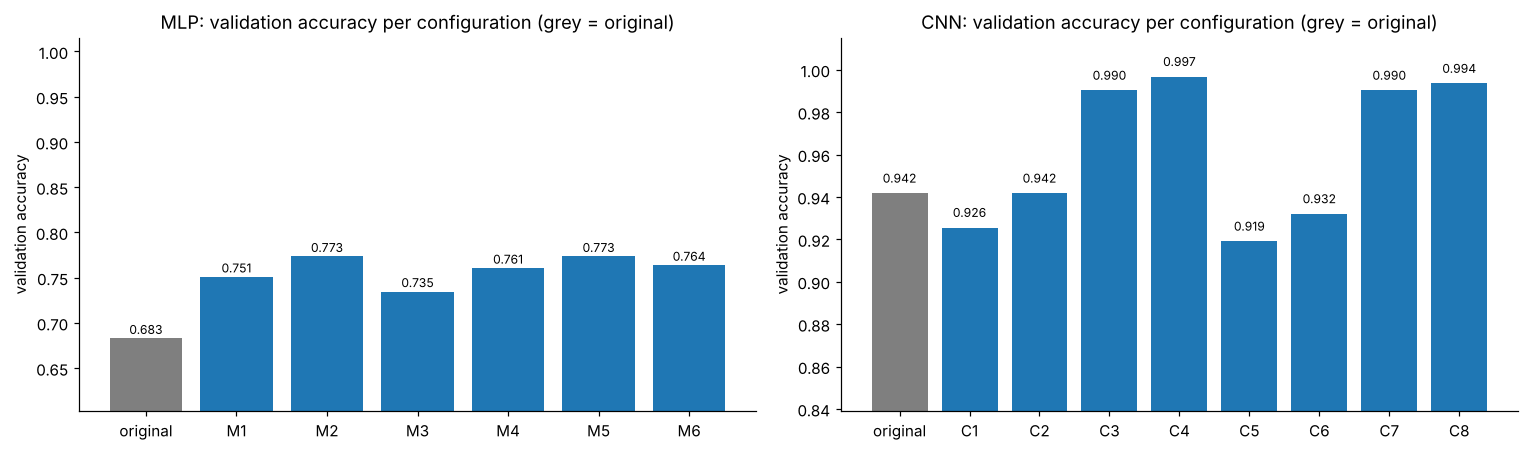

In [9]:
def pick(res):
    best = res.sort_values(["val acc", "val loss"], ascending=[False, True]).iloc[0]
    return json.loads(best["cfg"]), best["label"]

MLP_BEST, mlp_label = pick(mlp_res)
CNN_BEST, cnn_label = pick(cnn_res)
print(f"Selected MLP ({mlp_label}): {describe(MLP_BEST)}")
print(f"Selected CNN ({cnn_label}): {describe(CNN_BEST)}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, res, title in [(ax[0], mlp_res, "MLP"), (ax[1], cnn_res, "CNN")]:
    colors = ["tab:gray" if l == "original" else "tab:blue" for l in res["label"]]
    a.bar(res["label"], res["val acc"], color=colors)
    for i, v in enumerate(res["val acc"]):
        a.text(i, v + 0.005, f"{v:.3f}", ha="center", fontsize=8)
    lo = max(0, res["val acc"].min() - 0.08)
    a.set(ylim=(lo, 1.015), ylabel="validation accuracy", title=f"{title}: validation accuracy per configuration (grey = original)")
plt.tight_layout(); save("hp_search"); plt.show()

**Interpretation**

* **MLP.** The original configuration reached 68.3% validation accuracy. With standardised inputs and a lower learning rate (1e-4), all six configurations land between **73.5% and 77.3%**, and the selected model (M2: 256 → 128 units, dropout 0.5) reaches 77.3%. Quadrupling the size (1,024 → 256 units, 4.5 M parameters) does not help: training accuracy goes up to 99% while validation stays at 77%. The MLP's limit is **overfitting**, not capacity.
* **CNN.** **Data augmentation is the decisive hyperparameter.** Without it, every CNN sits between 91.9% and 94.2% (the original configuration: 94.2%). With it, validation accuracy jumps to **99.0–99.7%** and validation loss falls about 10× (0.22 → 0.02–0.03). Dropout and learning rate matter much less. With lr = 3e-4 the augmented models were still improving at the 100-epoch limit.
* **Why train accuracy is below validation accuracy** in the augmented CNNs (e.g. 91.9% vs 99.7%): training accuracy is measured on randomly rotated, shifted and zoomed images with dropout active, while validation images are clean. It is a harder task by design, not a bug.
* Selected for the final comparison: **MLP M2** and **CNN C4** (dropout 0.5, lr = 1e-3, augmentation).

## 5. Final comparison on the test set (5 seeds)

A single training run is noisy: with 310 test images, one image is 0.32 percentage points of accuracy.
The selected MLP and CNN are therefore each retrained from scratch with **5 different seeds**, and test metrics are reported as mean ± standard deviation.
Precision, recall and F1 are macro-averaged over the 10 classes; ROC-AUC is the macro average of one-vs-rest AUCs.

In [10]:
SEEDS = [0, 1, 2, 3, 4]

def test_metrics(p, y_true):
    pred = p.argmax(1)
    return {"accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, pred, average="macro"),
            "F1": f1_score(y_true, pred, average="macro"),
            "ROC-AUC": roc_auc_score(y_true, p, multi_class="ovr", average="macro")}

final = {}
for name, build_fn, cfg in [("MLP", build_mlp, MLP_BEST), ("CNN", build_cnn, CNN_BEST)]:
    final[name] = {"models": [], "hist": [], "probs": [], "rows": []}
    for s in SEEDS:
        model, h = fit(build_fn, cfg, f"final_{name.lower()}_seed{s}", X_tr, y_tr, X_va, y_va, seed=s)
        p = model.predict(X_te, verbose=0)
        final[name]["models"].append(model); final[name]["hist"].append(h); final[name]["probs"].append(p)
        final[name]["rows"].append(test_metrics(p, y_te))

summary = pd.concat({n: pd.DataFrame(v["rows"]).agg(["mean", "std"]).T for n, v in final.items()}, axis=1)
summary.columns = [f"{a} {b}" for a, b in summary.columns]
print("Test-set metrics over 5 seeds:")
display(summary.round(4))

acc = {n: np.array([r["accuracy"] for r in v["rows"]]) for n, v in final.items()}
diff = acc["CNN"] - acc["MLP"]
print(f"CNN − MLP accuracy per seed: {np.round(diff, 4)};  mean {diff.mean():.4f} ± {diff.std(ddof=1):.4f}")
print(f"Parameters: MLP {final['MLP']['models'][0].count_params():,} | CNN {final['CNN']['models'][0].count_params():,}")

Test-set metrics over 5 seeds:


,MLP mean,MLP std,CNN mean,CNN std
accuracy,0.7794,0.0084,0.9813,0.0035
precision,0.7843,0.0095,0.9819,0.0036
recall,0.7794,0.0084,0.9813,0.0035
F1,0.7796,0.0080,0.9814,0.0036
ROC-AUC,0.9684,0.0022,0.9970,0.0002


CNN − MLP accuracy per seed: [0.2097 0.1968 0.1903 0.2032 0.2097];  mean 0.2019 ± 0.0084
Parameters: MLP 1,083,018 | CNN 1,142,666


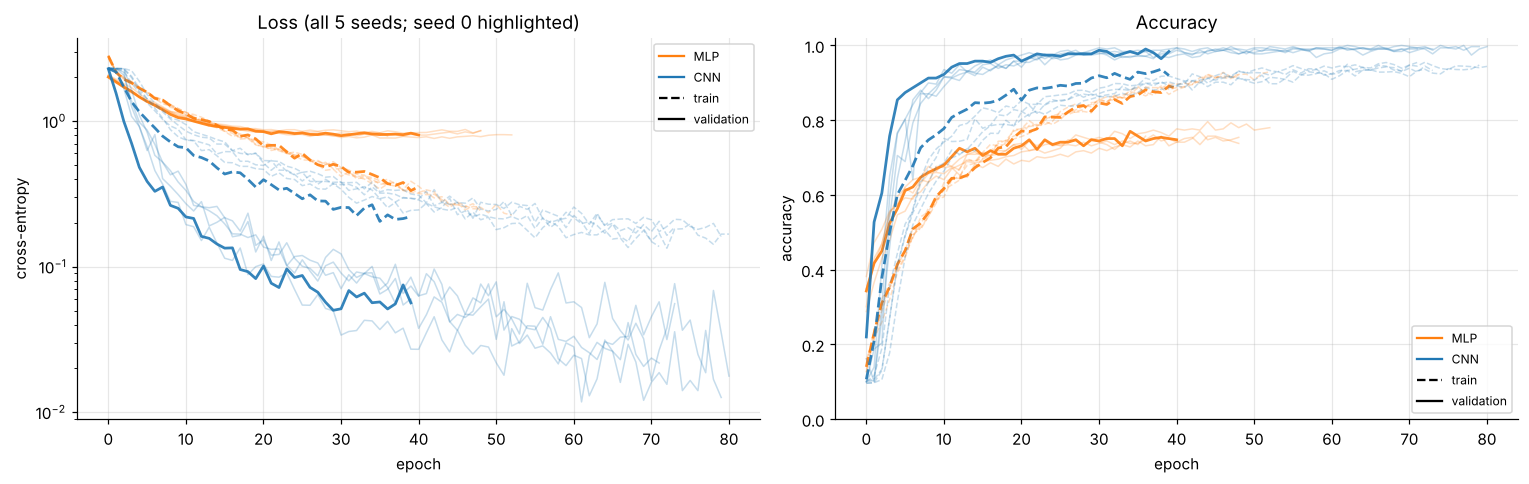

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, col in [("MLP", "tab:orange"), ("CNN", "tab:blue")]:
    for i, h in enumerate(final[name]["hist"]):
        kw = dict(color=col, alpha=0.9 if i == 0 else 0.25, lw=1.8 if i == 0 else 1)
        ax[0].plot(h["loss"], ls="--", **kw); ax[0].plot(h["val_loss"], ls="-", **kw)
        ax[1].plot(h["accuracy"], ls="--", **kw); ax[1].plot(h["val_accuracy"], ls="-", **kw)
from matplotlib.lines import Line2D
leg = [Line2D([], [], color="tab:orange", label="MLP"), Line2D([], [], color="tab:blue", label="CNN"),
       Line2D([], [], color="k", ls="--", label="train"), Line2D([], [], color="k", ls="-", label="validation")]
ax[0].set(title="Loss (all 5 seeds; seed 0 highlighted)", xlabel="epoch", ylabel="cross-entropy", yscale="log")
ax[1].set(title="Accuracy", xlabel="epoch", ylabel="accuracy", ylim=(0, 1.02))
for a in ax: a.legend(handles=leg, fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); save("learning_curves"); plt.show()

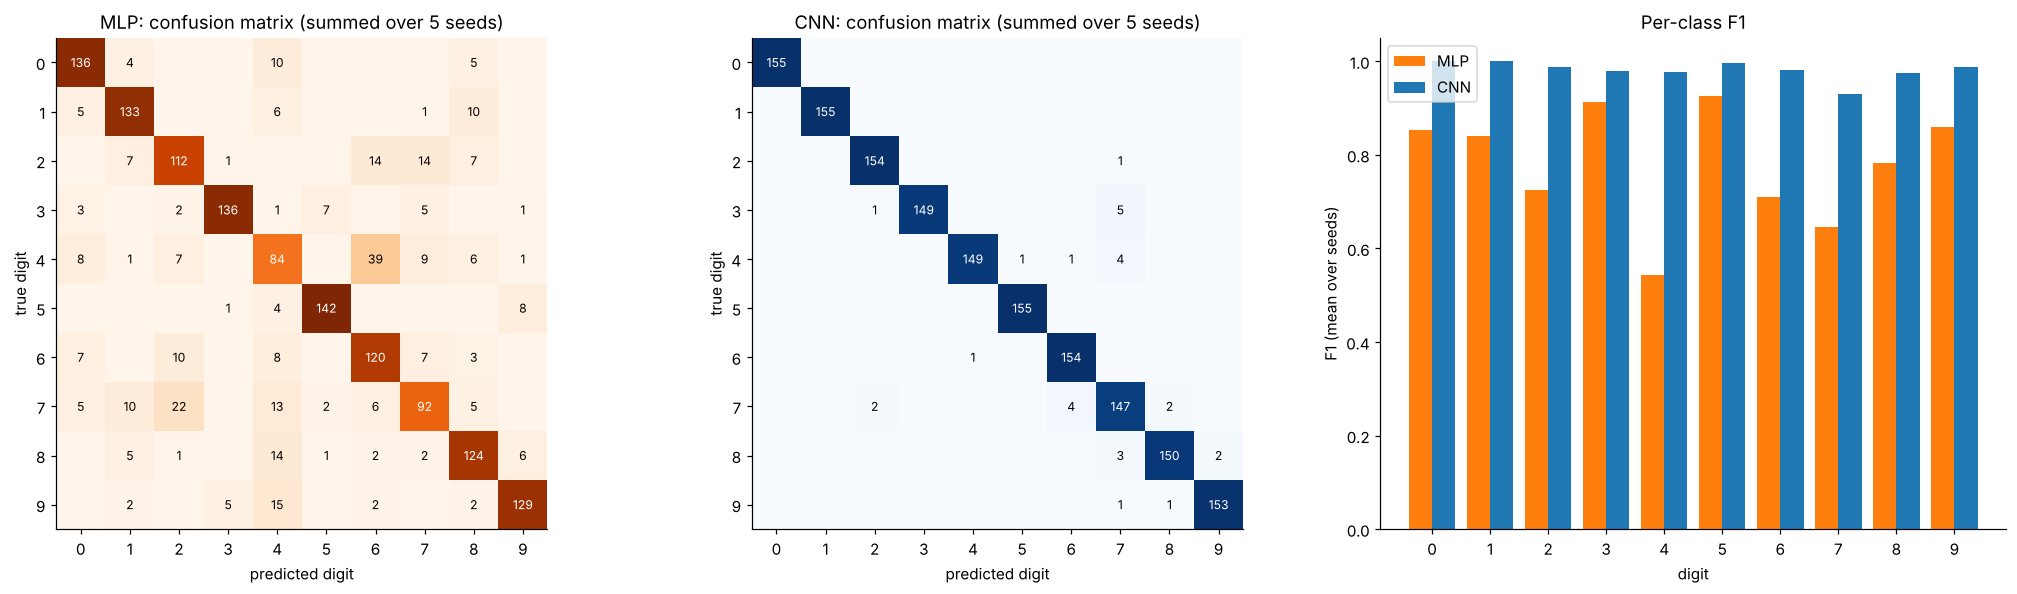

Most frequent errors, true→predicted (count over 5 seeds × 310 images):
  MLP: 4→6 (39), 7→2 (22), 9→4 (15), 8→4 (14), 2→7 (14)
  CNN: 3→7 (5), 7→6 (4), 4→7 (4), 8→7 (3), 8→9 (2)


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
for a, name, cmap in [(ax[0], "MLP", "Oranges"), (ax[1], "CNN", "Blues")]:
    cm = sum(confusion_matrix(y_te, p.argmax(1), labels=range(10)) for p in final[name]["probs"])  # summed over seeds
    a.imshow(cm, cmap=cmap)
    for i in range(10):
        for j in range(10):
            if cm[i, j]:
                a.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks(range(10)); a.set_yticks(range(10))
    a.set(title=f"{name}: confusion matrix (summed over 5 seeds)", xlabel="predicted digit", ylabel="true digit")
f1_cls = {n: np.mean([f1_score(y_te, p.argmax(1), average=None) for p in final[n]["probs"]], axis=0) for n in final}
xx = np.arange(10)
ax[2].bar(xx - 0.2, f1_cls["MLP"], 0.4, label="MLP", color="tab:orange")
ax[2].bar(xx + 0.2, f1_cls["CNN"], 0.4, label="CNN", color="tab:blue")
ax[2].set_xticks(xx); ax[2].set(ylim=(0, 1.05), xlabel="digit", ylabel="F1 (mean over seeds)", title="Per-class F1"); ax[2].legend()
plt.tight_layout(); save("confusion_per_class"); plt.show()

def top_confusions(name, k=5):
    cm = sum(confusion_matrix(y_te, p.argmax(1), labels=range(10)) for p in final[name]["probs"])
    np.fill_diagonal(cm, 0)
    flat = sorted(((cm[i, j], i, j) for i in range(10) for j in range(10) if cm[i, j]), reverse=True)[:k]
    return ", ".join(f"{i}→{j} ({c})" for c, i, j in flat)
print("Most frequent errors, true→predicted (count over 5 seeds × 310 images):")
print("  MLP:", top_confusions("MLP")); print("  CNN:", top_confusions("CNN"))

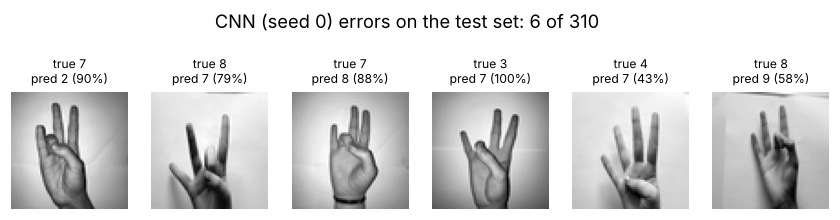

In [13]:
p0 = final["CNN"]["probs"][0]; wrong = np.where(p0.argmax(1) != y_te)[0]
n_show = min(10, len(wrong))
fig, ax = plt.subplots(1, max(n_show, 1), figsize=(1.6 * max(n_show, 1), 2.3))
ax = np.atleast_1d(ax)
for a, i in zip(ax, wrong[:n_show]):
    a.imshow(X_te[i, ..., 0], cmap="gray"); a.axis("off")
    a.set_title(f"true {y_te[i]}\npred {p0[i].argmax()} ({p0[i].max():.0%})", fontsize=8)
plt.suptitle(f"CNN (seed 0) errors on the test set: {len(wrong)} of {len(y_te)}", y=1.05)
save("cnn_errors"); plt.show()

**Interpretation: why the CNN wins**

* **Test results over 5 seeds:** CNN **98.1% ± 0.4%** accuracy (macro F1 0.981, ROC-AUC 0.997) vs MLP **77.9% ± 0.8%** (F1 0.780, ROC-AUC 0.968). The CNN is better on every seed by 19–21 points (mean 20.2 ± 0.8), far beyond seed-to-seed variation.
* **It is not about size.** Both models have ~1.1 M parameters (MLP 1.08 M, CNN 1.14 M). The difference is the **inductive bias**. Convolutions look for the same local pattern (an edge, a finger tip) everywhere in the image, and pooling tolerates small shifts. The MLP treats each of the 4,096 pixels as an unrelated input, so a hand moved by a few pixels looks like a different example, and with 1,443 training images it memorises instead of generalising.
* **Learning curves.** The MLP's validation loss stops improving at ~0.8 by epoch 15–20 while its training loss keeps falling: the classic overfitting gap. The CNN's validation loss keeps falling to ~0.02–0.06; its training loss stays *above* the validation loss because training batches are augmented.
* **Error analysis.** The MLP's most frequent errors are **4→6 (39 of 155 test predictions of digit 4 over 5 seeds)**, 7→2 (22), 9→4, 8→4 and 2→7. These are exactly the pairs with the most similar mean images (4–6: r = 0.97). Its weakest classes are 4 (F1 0.54) and 7 (0.65). The CNN makes only 29 errors in 1,550 predictions; the most common is 3→7 (5), and its weakest class is 7 (F1 0.93). The CNN tells signs apart by finger configuration, which raw pixel overlap cannot capture.
* **ROC-AUC is high even for the MLP (0.968)** because it usually ranks the correct digit near the top. Its top-1 mistakes are between look-alike classes, not random.
* **Compared with the first version** (single run, CNN 95.2%): the tuned, augmented CNN gains about 3 points, and the 5-seed evaluation shows the result is stable (sd 0.4 points).

## 6. Robustness to noise

Test images are corrupted with Gaussian noise, $\tilde x = \text{clip}(x + \varepsilon,\,0,\,1)$ with $\varepsilon\sim\mathcal N(0,\sigma^2)$, for $\sigma\in\{0, 0.1, 0.2, 0.3, 0.4\}$.
Four strategies are compared:

| | Strategy | Classifier trained on | Input at test time |
|---|---|---|---|
| A | clean CNN (Section 5) | clean images | noisy image |
| B | DAE + clean CNN | clean images | DAE(noisy image) |
| C | CNN on denoised data | DAE(noisy training images) | DAE(noisy image) |
| D | CNN with noise augmentation | clean images + random noise (σ = 0.2) added in every batch | noisy image |

**Denoising autoencoder (DAE).** A convolutional encoder (64×64 → 16×16×64) and decoder (upsampling back to 64×64, sigmoid output), trained with MSE to map noisy (σ = 0.2) to clean training images.
For strategy C, the training images are re-noised with a **different** random realisation before denoising, so the classifier does not see DAE outputs for the exact noisy inputs the DAE was fitted on.
A and B reuse the five Section-5 CNNs; C and D are trained with three seeds each. A run that never leaves the initial plateau (best validation accuracy ≤ 20%) is reported as a failed run and replaced by the next seed.

DAE: 74,497 parameters, stopped after 116 epochs


Validation MSE to clean image — noisy input: 0.0346;  DAE output: 0.0021


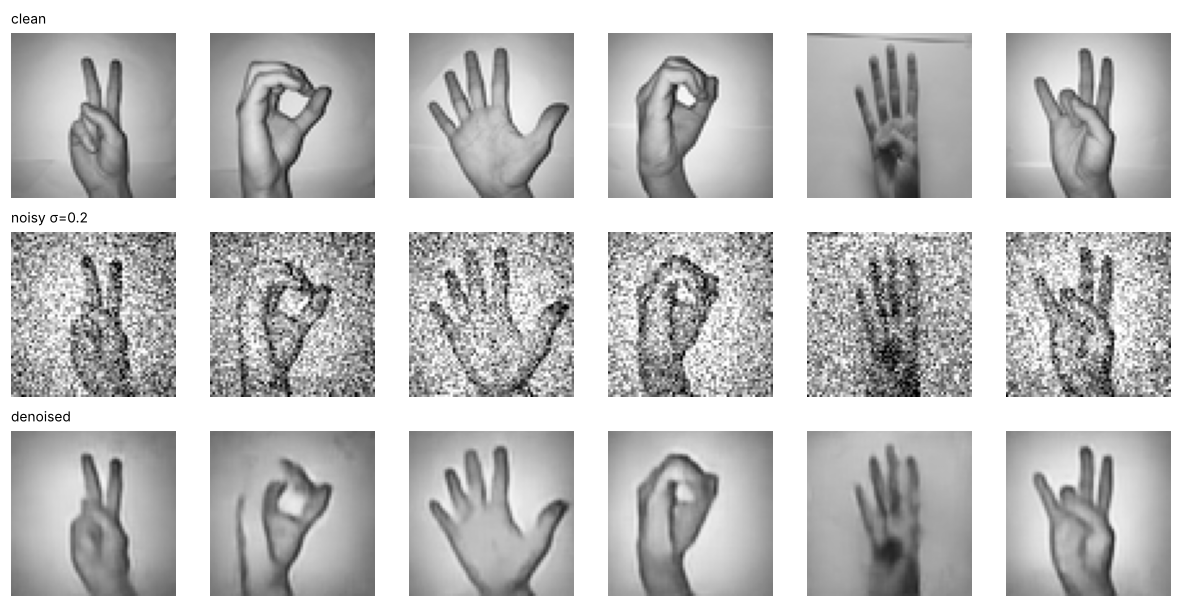

In [14]:
def add_noise(Xc, sigma, seed):
    return np.clip(Xc + np.random.default_rng(seed).normal(0, sigma, Xc.shape).astype("float32"), 0, 1)

def build_dae(cfg):
    inp = layers.Input((64, 64, 1))
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inp); x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x); x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.UpSampling2D()(x); x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.UpSampling2D()(x); out = layers.Conv2D(1, 3, padding="same", activation="sigmoid")(x)
    m = keras.Model(inp, out, name="dae")
    m.compile(keras.optimizers.Adam(cfg["lr"]), "mse")
    return m

dae, dae_hist = fit(build_dae, {"lr": 1e-3}, "dae", add_noise(X_tr, 0.2, 1), X_tr, add_noise(X_va, 0.2, 2), X_va,
                    max_epochs=150, patience=10)
noisy_va = add_noise(X_va, 0.2, 2)
mse = lambda a, b: float(np.mean((a - b) ** 2))
print(f"DAE: {dae.count_params():,} parameters, stopped after {len(dae_hist['loss'])} epochs")
print(f"Validation MSE to clean image — noisy input: {mse(noisy_va, X_va):.4f};  DAE output: {mse(dae.predict(noisy_va, verbose=0), X_va):.4f}")

idx = np.random.default_rng(3).choice(len(X_te), 6, replace=False)
noisy_ex = add_noise(X_te[idx], 0.2, 99); den_ex = dae.predict(noisy_ex, verbose=0)
fig, ax = plt.subplots(3, 6, figsize=(11, 5.6))
for j in range(6):
    for r, (img, t) in enumerate([(X_te[idx[j]], "clean"), (noisy_ex[j], "noisy σ=0.2"), (den_ex[j], "denoised")]):
        ax[r, j].imshow(img[..., 0], cmap="gray", vmin=0, vmax=1); ax[r, j].axis("off")
        if j == 0: ax[r, j].set_title(t, loc="left", fontsize=9)
plt.tight_layout(); save("dae_examples"); plt.show()

In [15]:
ROB_SEEDS = [0, 1, 2]
X_tr_den = dae.predict(add_noise(X_tr, 0.2, 11), verbose=0)        # different noise realisation from DAE training
X_va_den = dae.predict(add_noise(X_va, 0.2, 12), verbose=0)
def train_seeds(cfg, name, X_train, X_val, n=len(ROB_SEEDS)):
    # Train n models with consecutive seeds; a run that never leaves the initial plateau
    # (best validation accuracy <= 20%) is reported as failed and replaced by the next seed.
    models, failed, s = [], [], 0
    while len(models) < n:
        m, h = fit(build_cnn, cfg, f"{name}_seed{s}", X_train, y_tr, X_val, y_va, seed=s)
        (models if max(h["val_accuracy"]) > 0.2 else failed).append(m if max(h["val_accuracy"]) > 0.2 else s)
        s += 1
    print(f"{name}: {n} successful runs; failed seeds (stuck at chance level): {failed or 'none'}")
    return models

cnn_den = train_seeds(CNN_BEST, "rob_cnn_denoised", X_tr_den, X_va_den)
cnn_noise = train_seeds({**CNN_BEST, "noise": 0.2}, "rob_cnn_noiseaug", X_tr, X_va)

SIGMAS = [0.0, 0.1, 0.2, 0.3, 0.4]
rows = []
for sg in SIGMAS:
    Xn = add_noise(X_te, sg, 1000 + int(sg * 100)) if sg > 0 else X_te
    Xd = dae.predict(Xn, verbose=0)
    for strat, models, inp in [("A clean CNN", final["CNN"]["models"], Xn), ("B DAE + clean CNN", final["CNN"]["models"], Xd),
                               ("C CNN on denoised data", cnn_den, Xd), ("D CNN + noise augmentation", cnn_noise, Xn)]:
        for k, m in enumerate(models):
            p = m.predict(inp, verbose=0)
            rows.append({"strategy": strat, "sigma": sg, "seed": k, "accuracy": accuracy_score(y_te, p.argmax(1)),
                         "F1": f1_score(y_te, p.argmax(1), average="macro")})
rob = pd.DataFrame(rows)
rob_tab = rob.groupby(["strategy", "sigma"])["accuracy"].agg(["mean", "std"]).unstack("sigma")
display(rob_tab.round(3))

rob_cnn_denoised: 3 successful runs; failed seeds (stuck at chance level): none


rob_cnn_noiseaug: 3 successful runs; failed seeds (stuck at chance level): [2]


mean                                std         \
sigma                         0.0    0.1    0.2    0.3    0.4    0.0    0.1   
strategy                                                                      
A clean CNN                 0.981  0.894  0.472  0.255  0.186  0.004  0.025   
B DAE + clean CNN           0.967  0.963  0.965  0.914  0.722  0.009  0.007   
C CNN on denoised data      0.966  0.962  0.974  0.911  0.702  0.002  0.010   
D CNN + noise augmentation  0.981  0.970  0.919  0.783  0.548  0.006  0.010   

                                                 
sigma                         0.2    0.3    0.4  
strategy                                         
A clean CNN                 0.094  0.016  0.021  
B DAE + clean CNN           0.010  0.012  0.038  
C CNN on denoised data      0.009  0.016  0.051  
D CNN + noise augmentation  0.011  0.054  0.090

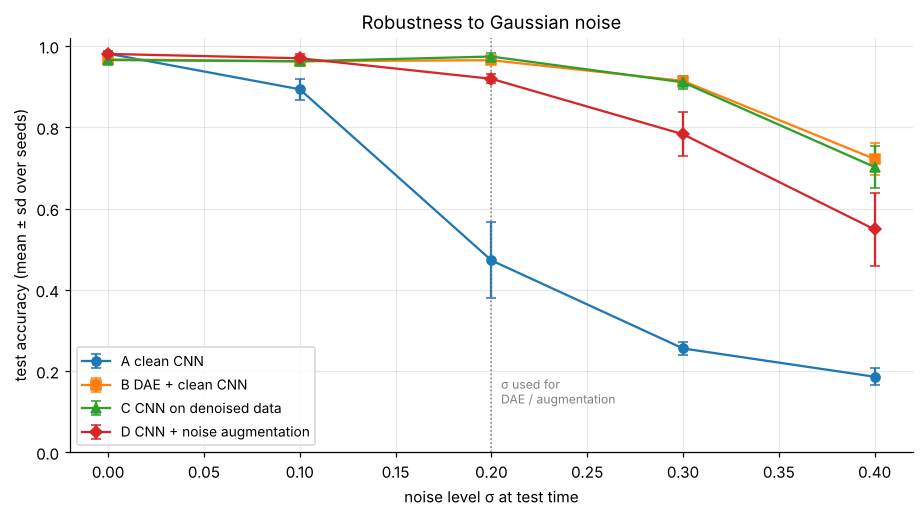

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for (strat, g), mk in zip(rob.groupby("strategy"), ["o", "s", "^", "D"]):
    s = g.groupby("sigma")["accuracy"].agg(["mean", "std"])
    ax.errorbar(s.index, s["mean"], yerr=s["std"], marker=mk, capsize=3, label=strat)
ax.axvline(0.2, color="gray", ls=":", lw=1); ax.text(0.205, 0.12, "σ used for\nDAE / augmentation", fontsize=8, color="gray")
ax.set(xlabel="noise level σ at test time", ylabel="test accuracy (mean ± sd over seeds)", ylim=(0, 1.02),
       title="Robustness to Gaussian noise"); ax.grid(alpha=0.3); ax.legend(fontsize=9, loc="lower left")
plt.tight_layout(); save("robustness"); plt.show()

**Interpretation**

* **The clean CNN is fragile.** Accuracy drops from 98.1% to 89.4% at σ = 0.1 and to **47.2%** at σ = 0.2 (with large seed-to-seed variation, sd 9 points). It never saw noise, and noise changes exactly the local textures its filters respond to.
* **The DAE works well as a denoiser.** It reduces the mean squared error to the clean image from 0.0346 to 0.0021 (16×). Placed in front of the same clean CNN (B), it keeps accuracy at **96.5% at σ = 0.2**, 91.4% at σ = 0.3 and 72.2% at σ = 0.4.
* **The cost of the DAE is a little blur.** On clean images, B and C score 96.7% instead of 98.1%: the reconstruction smooths fine details (finger edges) that the classifier uses.
* **Retraining the classifier on denoised images (C) adds almost nothing beyond B**: 97.4% vs 96.5% at σ = 0.2, the same within noise elsewhere. The robustness comes from the DAE, not from retraining. The first version of this project attributed it to retraining, but that model had been warm-started from saved weights, so the comparison was not valid.
* **Noise augmentation (D)** is the simplest option (one model, no extra network). It keeps the full clean accuracy (98.1%) and reaches 97.0% at σ = 0.1 and 91.9% at σ = 0.2, but degrades faster under heavier noise (54.8% at σ = 0.4 vs ~70% for the DAE pipelines). One of its first three seeds never left the initial plateau and was replaced; heavy regularisation (augmentation + noise + dropout 0.5) makes optimisation harder to start.
* **Which to choose?** If inputs are mostly clean with occasional mild noise, noise augmentation (D) gives the best overall trade-off. If heavy noise is expected, a DAE front-end (B) is more robust, at the price of ~1.5 points on clean images and a second network at inference time.
* **Limitation:** synthetic Gaussian noise is only one kind of degradation. Real camera images also vary in blur, lighting, background and hand orientation, which this experiment does not test.

## Summary

In [17]:
s = summary
print(f"MLP: accuracy {s.loc['accuracy','MLP mean']:.3f} ± {s.loc['accuracy','MLP std']:.3f}, ROC-AUC {s.loc['ROC-AUC','MLP mean']:.3f}")
print(f"CNN: accuracy {s.loc['accuracy','CNN mean']:.3f} ± {s.loc['accuracy','CNN std']:.3f}, ROC-AUC {s.loc['ROC-AUC','CNN mean']:.3f}")
r = rob.groupby(["strategy", "sigma"])["accuracy"].mean().unstack()
print("Accuracy at σ = 0.2:", "; ".join(f"{k}: {v:.3f}" for k, v in r[0.2].items()))

MLP: accuracy 0.779 ± 0.008, ROC-AUC 0.968
CNN: accuracy 0.981 ± 0.004, ROC-AUC 0.997
Accuracy at σ = 0.2: A clean CNN: 0.472; B DAE + clean CNN: 0.965; C CNN on denoised data: 0.974; D CNN + noise augmentation: 0.919


* **CNN vs MLP:** 98.1% ± 0.4% vs 77.9% ± 0.8% test accuracy with similar parameter counts. Spatial inductive bias (local filters, weight sharing, pooling) plus data augmentation is what makes the difference on a small image dataset.
* **Hyperparameters:** augmentation was the single most important choice for the CNN (+5 points on validation); input standardisation and a lower learning rate fixed the MLP's unstable training.
* **Robustness:** a denoising autoencoder in front of the classifier is the most robust option under heavy noise; noise augmentation is simpler and costs nothing on clean images.
* **Reproducibility:** every model is trained from scratch with fixed seeds; checkpoints are only for resuming or re-evaluating, never for silently continuing training.